In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math
import plotly.graph_objects as go

In [3]:
def associated_legendre(l,m,x):
    if isinstance(l, bool) or not isinstance(l, (int, np.integer)):
        raise TypeError("l must be an integer.")
    if isinstance(m, bool) or not isinstance(m, (int, np.integer)):
        raise TypeError("m must be an integer.")
    if l < 0:
        raise ValueError("l must be non-negative.")
    if m < 0 or m > l:
        raise ValueError("m must satisfy 0 <= m <= l.")

    x_arr = np.asarray(x, dtype=float)

    if not np.all(np.isfinite(x_arr)):
        raise ValueError("All values of x must be finite.")

    if np.any(x_arr < -1) or np.any(x_arr > 1):
        raise ValueError("All values of x must lie in the interval [-1, 1].")

    sqrt_term = np.sqrt(np.clip(1.0 - x_arr**2, 0.0, None))

    p_mm = np.ones_like(x_arr, dtype=float)

    for order in range(1, m + 1):
        p_mm = -(2 * order - 1) * sqrt_term * p_mm

    if l == m:
        return p_mm

    p_mplus1_m = (2 * m + 1) * x_arr * p_mm
    if l == m + 1:
        return p_mplus1_m

    p_previous_previous = p_mm
    p_previous = p_mplus1_m

    for degree in range(m + 2, l + 1):

        p_current = (
            (2 * degree - 1) * x_arr * p_previous
            - (degree + m - 1) * p_previous_previous
        ) / (degree - m)

        p_previous_previous = p_previous
        p_previous = p_current

    return p_previous

In [ ]:
def spherical_harmonic(l,m,theta,phi):
    if isinstance(l, bool) or not isinstance(l, (int, np.integer)):
        raise TypeError("l must be an integer.")
    if isinstance(m, bool) or not isinstance(m, (int, np.integer)):
        raise TypeError("m must be an integer.")
    if l < 0:
        raise ValueError("l must be non-negative.")
    if m < -l or m > l:
        raise ValueError("m must satisfy -l <= m <= l.")

    theta_arr = np.asarray(theta, dtype=float)
    phi_arr   = np.asarray(phi, dtype=float)

    m_abs = abs(m)

    x = np.cos(theta_arr)
    legendre_part = associated_legendre(l,m_abs,x)

    normalization_numerator = ((2*l + 1)*math.factorial(l - m_abs))
    normalization_denominator = (4*np.pi*math.factorial(l + m_abs))
    normalization = np.sqrt(normalization_numerator/normalization_denominator)

    phase_term = np.exp(1j*m_abs*phi_arr)
    y_positive = (normalization*legendre_part*phase_term)

    if m >= 0:
        return y_positive

    return (-1)**m_abs * np.conjugate(y_positive)

In [5]:
def probability_density(l,m,n_theta,n_phi):
    if isinstance(n_theta, bool) or not isinstance(n_theta, (int, np.integer)):
        raise TypeError("n_theta must be an integer.")
    if isinstance(n_phi, bool) or not isinstance(n_phi, (int, np.integer)):
        raise TypeError("n_phi must be an integer.")
    if n_theta < 2:
        raise ValueError("n_theta must be at least 2.")
    if n_phi < 2:
        raise ValueError("n_phi must be at least 2.")

    theta_arr = np.linspace(0,np.pi,n_theta)
    phi_arr = np.linspace(0,2*np.pi,n_phi,endpoint=False)

    theta_grid, phi_grid = np.meshgrid(theta_arr,phi_arr,indexing="ij")

    y_lm = spherical_harmonic(l,m,theta_grid,phi_grid)

    density = np.abs(y_lm)**2

    return theta_grid, phi_grid, density

In [8]:
def cartesian_coordinates(theta_grid,phi_grid,density):
    theta_grid = np.asarray(theta_grid)
    phi_grid   = np.asarray(phi_grid)
    density    = np.asarray(density)

    if not (theta_grid.shape== phi_grid.shape== density.shape):
        raise ValueError("theta_grid, phi_grid, and density must have the same shape.")

    if not np.isrealobj(density):
        raise ValueError("Probability density must be real-valued.")

    if np.any(density < 0):
        raise ValueError("Probability density must be non-negative.")

    if not (np.all(np.isfinite(theta_grid))and np.all(np.isfinite(phi_grid))and np.all(np.isfinite(density))):
        raise ValueError("Input arrays must contain only finite values.")

    x_coord = density * np.sin(theta_grid) * np.cos(phi_grid)
    y_coord = density * np.sin(theta_grid) * np.sin(phi_grid)
    z_coord = density * np.cos(theta_grid)

    return x_coord,y_coord,z_coord

In [6]:
def plot_probability_density(x_coord,y_coord,z_coord,density,l,m):
    x_coord = np.asarray(x_coord, dtype=float)
    y_coord = np.asarray(y_coord, dtype=float)
    z_coord = np.asarray(z_coord, dtype=float)
    density = np.asarray(density, dtype=float)

    if not (x_coord.shape == y_coord.shape == z_coord.shape == density.shape):
        raise ValueError("x_coord, y_coord, z_coord, and density must have the same shape.")

    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')

    density_max = np.max(density)

    if density_max == 0:
        normalized_density = np.zeros_like(density)
    else:
        normalized_density = density / density_max

    cmap = plt.cm.viridis
    face_colours = cmap(normalized_density)

    ax.plot_surface(x_coord,y_coord,z_coord,facecolors=face_colours,rstride=1,cstride=1,linewidth=0,antialiased=True,shade=False)

    norm = colors.Normalize(vmin=np.min(density), vmax=np.max(density))
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    fig.colorbar(sm, ax=ax, shrink=0.7, pad=0.1, label='Probability Density')

    limit = max(np.max(np.abs(x_coord)),np.max(np.abs(y_coord)),np.max(np.abs(z_coord)))

    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.set_zlim(-limit, limit)
    ax.set_box_aspect((1, 1, 1))

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(rf"Angular Probability Density $|Y_{{{l}}}^{{{m}}}(\theta,\phi)|^2$")

    ax.view_init(elev=25, azim=35)
    plt.show()

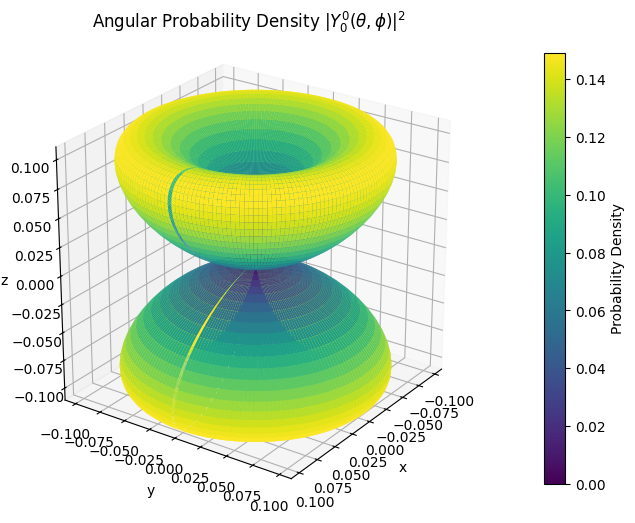

In [11]:
theta_grid, phi_grid, density = probability_density(2,1,100,200)
x_coord, y_coord, z_coord = cartesian_coordinates(theta_grid,phi_grid,density)
plot_probability_density(x_coord,y_coord,z_coord,density,0,0)